In [1]:
import pandas as pd
from pandas.api.types import CategoricalDtype
import numpy as np
import json
import time
import xarray as xr
import scipy.signal as signal
import glob
import os
import xgboost as xgb
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score, StratifiedKFold, permutation_test_score, GridSearchCV
from sklearn.metrics import classification_report, recall_score, confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score,make_scorer,balanced_accuracy_score, f1_score

import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
import seaborn as sns

from matplotlib.ticker import MultipleLocator


data_dir = '/home/lukeew/Local_work/data/01_SLW_xgb'
reference_dir = data_dir + '/CHCH_v3_reference/'
reference_mask_dir = reference_dir + 'processed{}/'
model_save_dir = reference_dir + 'models/'

model_mask_dir = data_dir + '/CHCH_v3_model_processed/{}/model_processed_{}/'

output_dir = data_dir + '/CHCH_v3_model_processed/figures/model_comp_panels/'


In [2]:
cmap1 = colors.ListedColormap([[0,0,0,0],[0.03137254901960784,0.18823529411764706,0.4196078431372549,1]])
cmap2 = colors.ListedColormap([[0,0,0,0],[0.8,0,0,1]])
cmap3 = colors.ListedColormap([[0,0,0,0],[0,0,1,1]])
cmap4 = colors.ListedColormap([[0,0,0,0],[0.8,0.8,0,1]])
cmap5 = colors.ListedColormap([[0,0,0,0],[0.7,0.7,0.7,1]])

c1 = (0.03137254901960784,0.18823529411764706,0.4196078431372549,1)
c2 = (0.8,0,0,1)    
c3 = (0,0,1)
c4 = (0.8,0.8,0)
c5 = (0.7,0.7,0.7)

### Single model case

In [4]:
date = '20210518'
model_name = 'model_002'

infile_ref = reference_mask_dir.format(date[:-2])+str(date)+'.nc'
print('  <--- ' + infile_ref)
ds_ref = xr.open_dataset(infile_ref)

infile_mod = model_mask_dir.format(model_name,date[:-2])+str(date)+'.nc'
print('  <--- ' + infile_mod)
ds_mod = xr.open_dataset(infile_mod)


  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_reference/processed202105/20210518.nc
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_model_processed/model_002/model_processed_202105/20210518.nc


In [5]:
# ds_ref
ds_mod

<xarray.Dataset>
Dimensions:           (time: 288, level: 300)
Coordinates:
  * time              (time) datetime64[ns] 2021-05-18T00:02:29.999991 ... 20...
    zfull             (level) float64 ...
Dimensions without coordinates: level
Data variables:
    backscatter       (time, level) float64 ...
    cloud_mask        (time, level) int8 ...
    temp              (time, level) float64 ...
    classified_peaks  (time, level) float64 ...
    wlwc              (time, level) int8 ...
    slwc              (time, level) int8 ...
    mpc               (time, level) int8 ...
    ic                (time, level) int8 ...
    wlwc_t            (time) int8 ...
    slwc_t            (time) int8 ...
    mpc_t             (time) int8 ...
    ic_t              (time) int8 ...

In [6]:
time = ds_mod.time
altitude = ds_mod.zfull.values

vdr = ds_ref.vdr
vdr_cm = ds_ref.vdr_cm

wlwc_ref = ds_ref.wlwc
slwc_ref = ds_ref.slwc
mpc_ref = ds_ref.mpc
ic_ref = ds_ref.ic
unknown_ref = ds_ref.unknown

slwc_t_ref = slwc_ref.max(dim='level')

# Optional step to tidy appearance of vdr data
# vdr = np.where((vdr>1), np.nan, vdr)
# vdr = np.where((vdr<0), np.nan, vdr)

backscatter = ds_mod.backscatter
temp = ds_mod.temp.values
cloud_mask = ds_mod.cloud_mask

class_pks = ds_mod.classified_peaks
pks_t = ~class_pks.max(dim='level').isnull()  # True if peaks are present, false if no peaks present

wlwc_mod = ds_mod.wlwc
slwc_mod = ds_mod.slwc
mpc_mod = ds_mod.mpc
ic_mod = ds_mod.ic

slwc_t_mod = ds_mod.slwc_t

In [48]:
pks_t.values.astype(int)

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0])

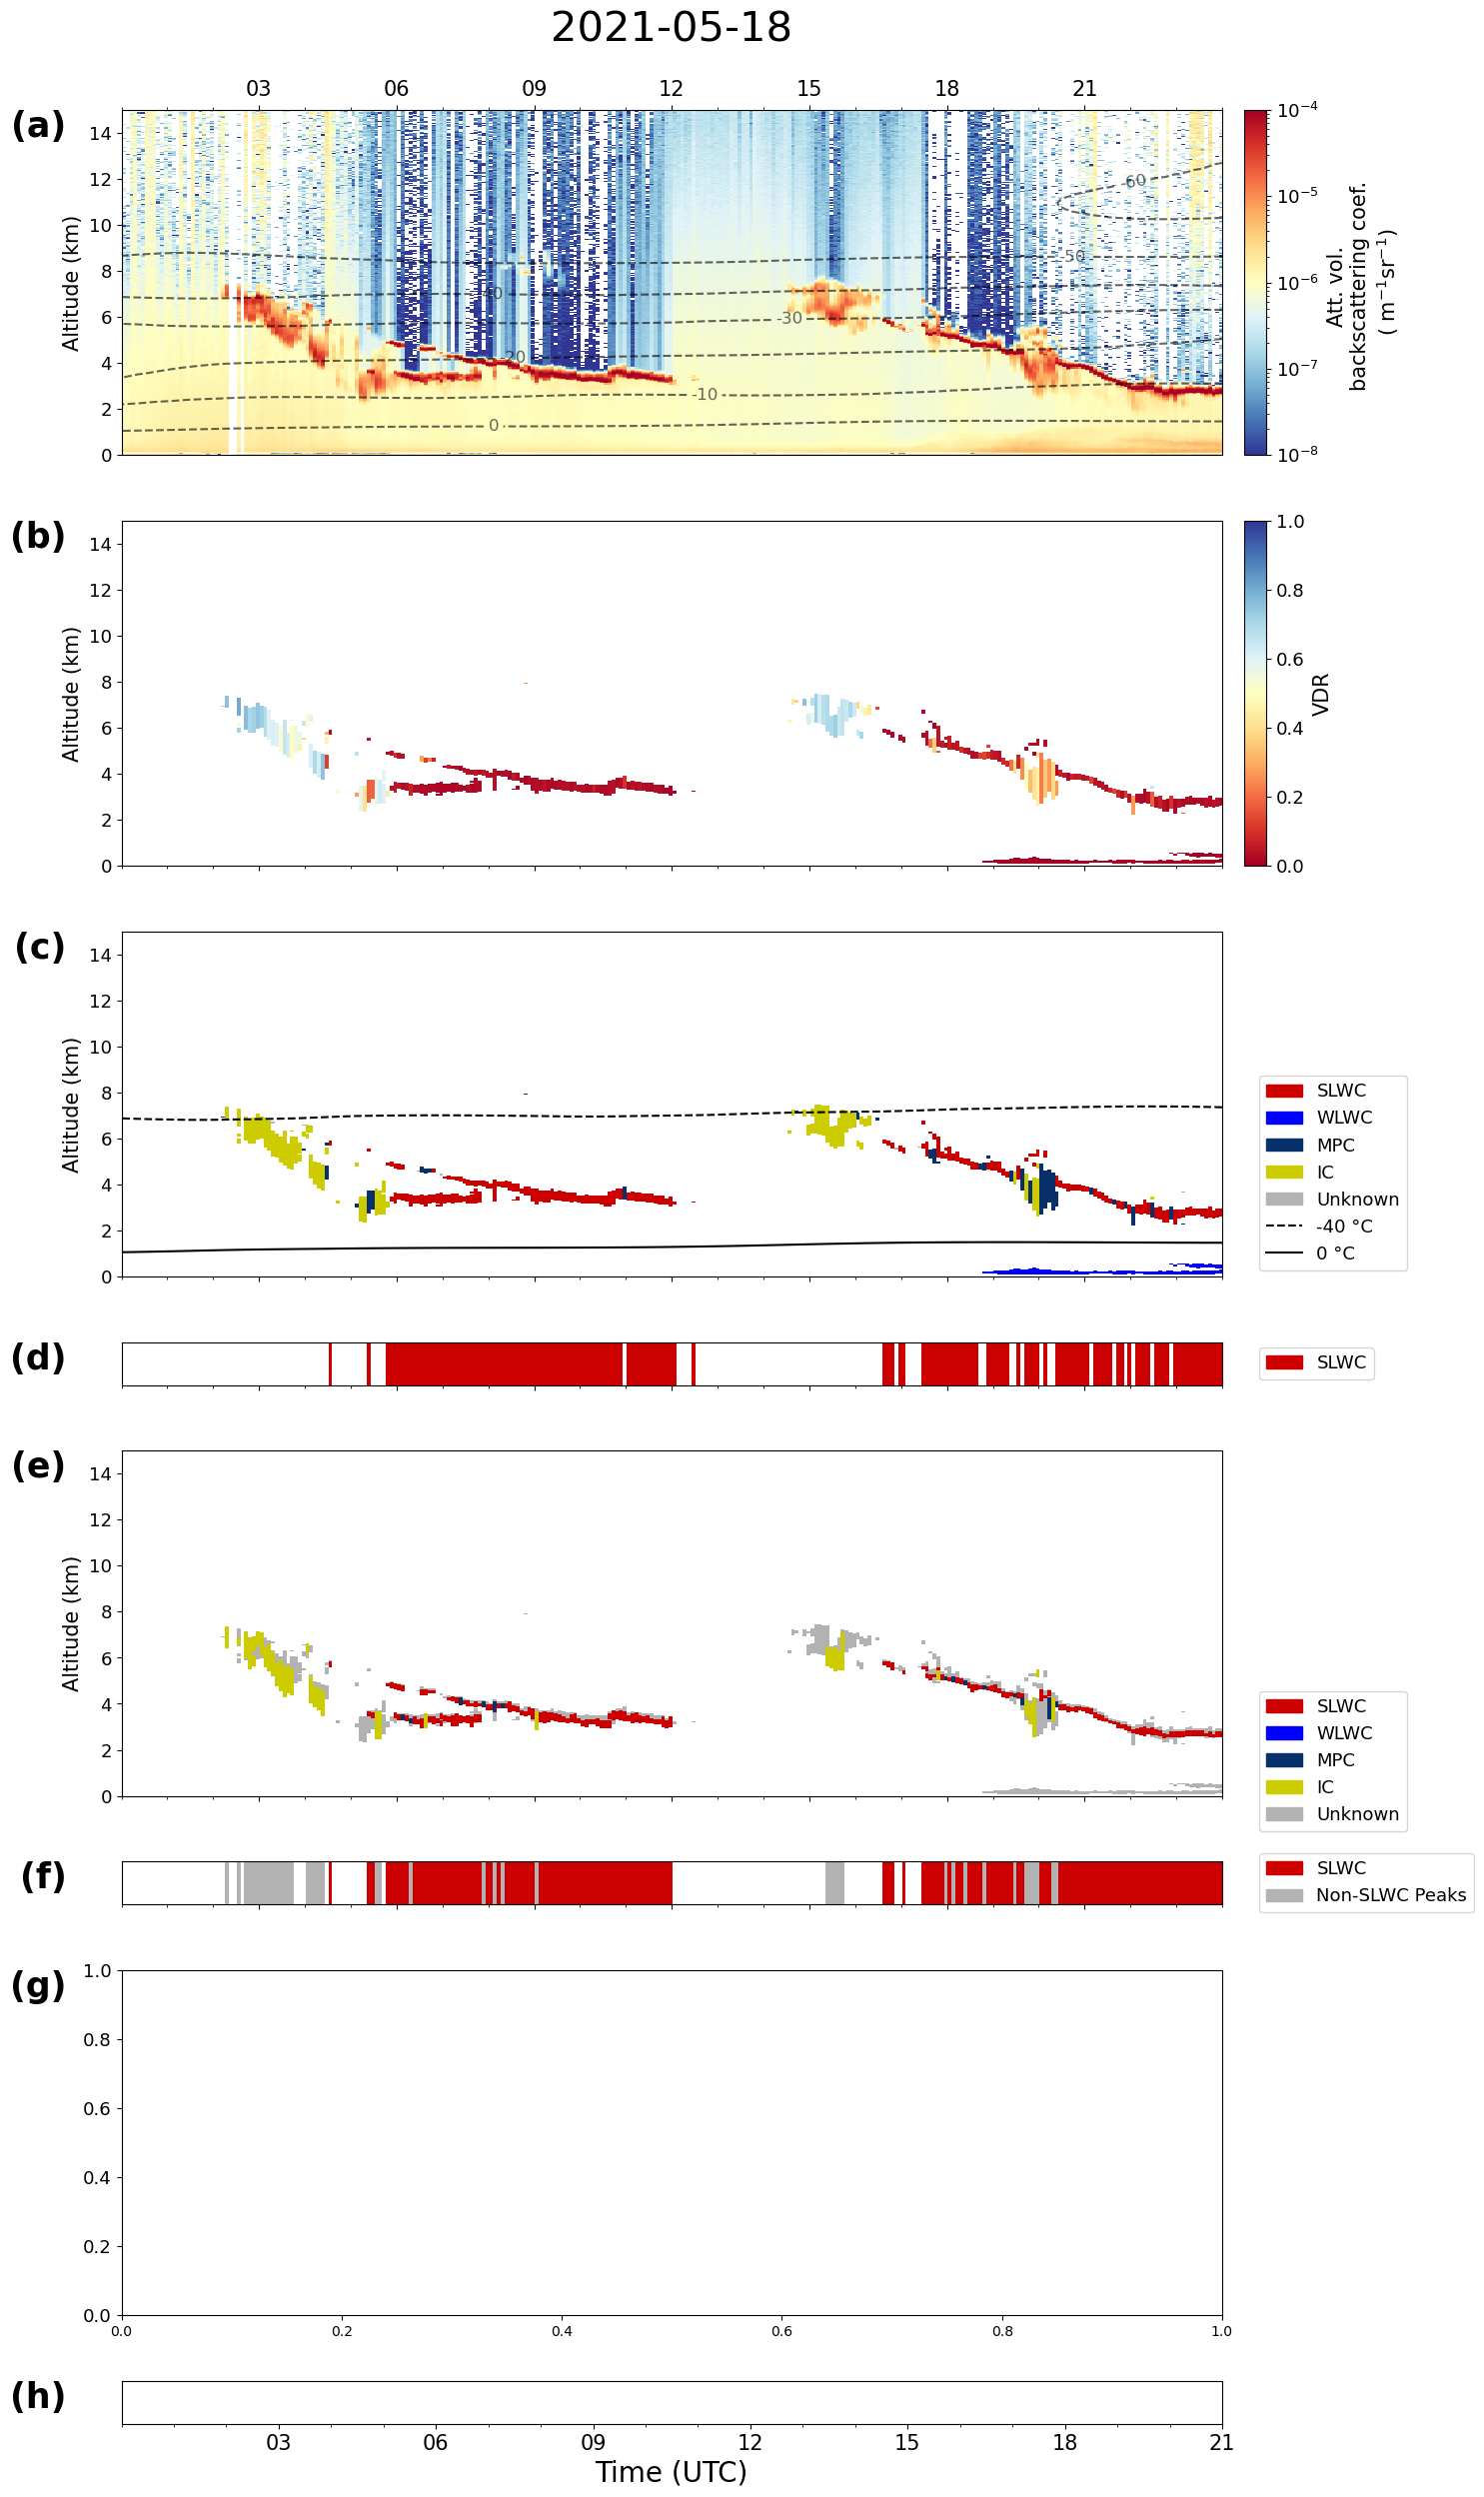

In [57]:
### Plot figure

gridspec_kw = {
    'height_ratios':[8,8,8,1,8,1,8,1],
    # 'hspace':0.2
    }

fig, axes = plt.subplots(8,figsize=(15,25), gridspec_kw=gridspec_kw)
(ax1, ax2, ax3, ax4, ax5, ax6, ax7,ax8) = axes

## Fig 1 - ALCF backscatter

Im1=ax1.imshow(backscatter[:].T,
    extent=(0, 288, 0, 15),
    aspect='auto',
    origin='lower',
    interpolation='None',
    cmap='RdYlBu_r',
    norm=colors.LogNorm(vmin=1e-8,vmax=1e-4),
    
)

cax1 = ax1.inset_axes([1.02,0,0.02,1],transform=ax1.transAxes)

fig.colorbar(Im1,
        extend='neither',
        cax=cax1,
    ).set_label(label='Att. vol. \nbackscattering coef. \n( m$^{-1}$sr$^{-1}$)', size=15, labelpad=6)

ax1.set_ylabel('Altitude (km)', fontsize=15)
ax1.set_xticklabels([])
ax1.set_xticks(np.arange(36,288,36))
ax1.xaxis.set_minor_locator(MultipleLocator(12))
cax1.tick_params(labelsize=13)

CS=ax1.contour(temp[:].T,
            levels=[-60,-50,-40,-30,-20,-10,0],
            colors='k',
            alpha=0.6,
            linestyles='dashed',
            extent=(0, 288, 0, 15),
            )

ax1.clabel(CS,inline=True,fontsize=12,fmt='%.0f')

## Fig 2 - VDR raw data
    
# Im2=ax2.imshow(vdr[:].T,
Im2=ax2.imshow(vdr_cm[:].T,             
    extent=(0, 288, 0, 15),
    aspect='auto',
    origin='lower',
    vmin=0,
    vmax=1,
    interpolation='None',
    cmap='RdYlBu'
)

ax2.set_xticklabels([])
ax2.set_xticks(np.arange(36,288,36))
ax2.xaxis.set_minor_locator(MultipleLocator(12))
ax2.set_ylabel('Altitude (km)', fontsize=15)

cax2 = ax2.inset_axes([1.02,0,0.02,1],transform=ax2.transAxes)

fig.colorbar(Im2,
        extend='neither',
        cax=cax2,
    ).set_label(label='VDR', size=15, labelpad=6)

cax2.tick_params(labelsize=13)




## Fig 3 - Reference (VDR) mask

Im3=ax3.imshow(ic_ref.T,
    extent=(0, 288, 0, 15),
    aspect='auto',
    origin='lower',
    vmin=0,
    vmax=1,
    interpolation='None',
    cmap=cmap4
)

Im3=ax3.imshow(mpc_ref.T,
    extent=(0, 288, 0, 15),
    aspect='auto',
    origin='lower',
    vmin=0,
    vmax=1,
    interpolation='None',
    cmap=cmap1
)

Im3=ax3.imshow(slwc_ref.T,
    extent=(0, 288, 0, 15),
    aspect='auto',
    origin='lower',
    vmin=0,
    vmax=1,
    interpolation='None',
    cmap=cmap2
)

Im3=ax3.imshow(wlwc_ref.T,
    extent=(0, 288, 0, 15),
    aspect='auto',
    origin='lower',
    vmin=0,
    vmax=1,
    interpolation='None',
    cmap=cmap3
)

Im3=ax3.imshow(unknown_ref.T,
    extent=(0, 288, 0, 15),
    aspect='auto',
    origin='lower',
    vmin=0,
    vmax=1,
    interpolation='None',
    cmap=cmap5
)

ax3.set_xticklabels([])
ax3.set_xticks(np.arange(36,288,36))
ax3.xaxis.set_minor_locator(MultipleLocator(12))
ax3.set_ylabel('Altitude (km)', fontsize=15)

ax3.contour(temp[:].T,
            levels=[-40,0],
            colors='k',
            linestyles=['dashed','solid'],
            extent=(0, 288, 0, 15),
            )


colour_labels = ['SLWC', 'WLWC', 'MPC','IC', 'Unknown']
patch_colors = [ c2, c3, c1, c4, c5]
patches_colours = [ mpatches.Patch(color=patch_colors[i], label=colour_labels[i] ) for i in range(5) ]

patch_linestyles = ['dashed', 'solid']
linestyle_labels = ['-40 \N{DEGREE SIGN}C', '0 \N{DEGREE SIGN}C']
patches_lines = [mlines.Line2D([],[],color='k',linestyle=patch_linestyles[i], label=linestyle_labels[i]) for i in range(2)] 
patches = patches_colours + patches_lines
ax3.legend(handles=patches, bbox_to_anchor=(1.025, 0.3), loc=6, fontsize=13)#,borderaxespad=0. )


    
## Fig 4 - Reference mask profile view

# Used to show idcs of 
# Im4=ax4.imshow([~np.isnan(SLCC_j_ts)],
#    	extent=(0, 288, 0, 1),
#    	aspect='auto',
#    	origin='lower',
#     # vmin=0,
#     # vmax=1,
#     interpolation='None',
#     cmap=cmap4
# )
Im4=ax4.imshow([slwc_t_ref],
    extent=(0, 288, 0, 1),
    aspect='auto',
    origin='lower',
    # vmin=0,
    # vmax=1,
    interpolation='None',
    cmap=cmap2
)


# unique_ts
ax4.set_xticklabels([])
ax4.set_yticklabels([])
ax4.set_xticks(np.arange(36,288,36))
ax4.set_yticks([])
ax4.xaxis.set_minor_locator(MultipleLocator(12))    

colour_labels = ['SLWC']
patch_colors = [ c2]
patches = [ mpatches.Patch(color=patch_colors[i], label=colour_labels[i] ) for i in range(1) ]

ax4.legend(handles=patches, bbox_to_anchor=(1.025, 0.5), loc=6, fontsize=13)




## Fig 5 - Model

Im5=ax5.imshow(cloud_mask.T,
    extent=(0, 288, 0, 15),
    aspect='auto',
    origin='lower',
    vmin=0,
    vmax=1,
    interpolation='None',
    cmap=cmap5
)

Im5=ax5.imshow(ic_mod[:].T,
    extent=(0, 288, 0, 15),
    aspect='auto',
    origin='lower',
    vmin=0,
    vmax=1,
    interpolation='None',
    cmap=cmap4
)

Im5=ax5.imshow(slwc_mod.T,
    extent=(0, 288, 0, 15),
    aspect='auto',
    origin='lower',
    vmin=0,
    vmax=1,
    interpolation='None',
    cmap=cmap2
)

Im5=ax5.imshow(wlwc_mod.T,
    extent=(0, 288, 0, 15),
    aspect='auto',
    origin='lower',
    vmin=0,
    vmax=1,
    interpolation='None',
    cmap=cmap3
)

Im5=ax5.imshow(mpc_mod.T,
    extent=(0, 288, 0, 15),
    aspect='auto',
    origin='lower',
    vmin=0,
    vmax=1,
    interpolation='None',
    cmap=cmap1
)


ax5.set_xticklabels([])
ax5.set_xticks(np.arange(36,288,36))
ax5.xaxis.set_minor_locator(MultipleLocator(12))
ax5.set_ylabel('Altitude (km)', fontsize=15)



colour_labels = ['SLWC', 'WLWC', 'MPC','IC', 'Unknown']
patch_colors = [ c2, c3, c1, c4, c5]
patches_two = [ mpatches.Patch(color=patch_colors[i], label=colour_labels[i] ) for i in range(5) ]

ax5.legend(handles=patches_two, bbox_to_anchor=(1.025, 0.1), loc=6, fontsize=13)#,borderaxespad=0. )


    
## Fig 6 - G22-Davis profile view

Im6=ax6.imshow([pks_t.values.astype(int)],
    extent=(0, 288, 0, 1),
    aspect='auto',
    origin='lower',
    vmin=0,
    vmax=1,
    interpolation='None',
    cmap=cmap5
)

Im6=ax6.imshow([slwc_t_mod],
    extent=(0, 288, 0, 1),
    aspect='auto',
    origin='lower',
    vmin=0,
    vmax=1,
    interpolation='None',
    cmap=cmap2
)




colour_labels = ['SLWC', 'Non-SLWC Peaks']
patch_colors = [ c2, c5]
patches_one = [ mpatches.Patch(color=patch_colors[i], label=colour_labels[i] ) for i in range(2) ]

ax6.legend(handles=patches_one, bbox_to_anchor=(1.025, 0.5), loc=6, fontsize=13)

ax6.set_xticklabels([])
ax6.set_yticklabels([])
ax6.set_xticks(np.arange(36,288,36))
ax6.set_yticks([])
ax6.xaxis.set_minor_locator(MultipleLocator(12))   






# ## Fig 7 - G22-Chch mask
# #Used print(plt.cm.datad["Blues"]) to get RGB values of Blues, RdYlGn cmaps

# #ICC
# Im7=ax7.imshow(g22chch_ice[:].T,
# # Im7=ax7.imshow((np.isnan(Z_ij))[:].T,
# # Im7=ax7.imshow((Z_ij==0)[:].T,
#     extent=(0, 288, 0, 15),
#     aspect='auto',
#     origin='lower',
#     vmin=0,
#     vmax=1,
#     interpolation='None',
#     cmap=cmap4
# )

# #SLCC
# Im7=ax7.imshow((Z_ij==1).T,
#     extent=(0, 288, 0, 15),
#     aspect='auto',
#     origin='lower',
#     vmin=0,
#     vmax=1,
#     interpolation='None',
#     cmap=cmap2
# )

# #WLCC
# Im7=ax7.imshow((Z_ij==2).T,
#     extent=(0, 288, 0, 15),
#     aspect='auto',
#     origin='lower',
#     vmin=0,
#     vmax=1,
#     interpolation='None',
#     cmap=cmap3
# )

# ax7.set_xticklabels([])
# ax7.set_xticks(np.arange(36,288,36))
# ax7.xaxis.set_minor_locator(MultipleLocator(12))
# ax7.set_ylabel('Altitude (km)', fontsize=15)

# colour_labels = ['SLCC','WLCC','ICC']
# patch_colors = [ c2,c3, c4]
# patches_two = [ mpatches.Patch(color=patch_colors[i], label=colour_labels[i] ) for i in range(3) ]



# ax7.legend(handles=patches_two, bbox_to_anchor=(1.025, 0.1), loc=6, fontsize=13)#,borderaxespad=0. )


    
## Fig 8 - G22-Chch profile view
    
# #ICC
# Im8=ax8.imshow([np.any(((Z_j_ICC==1),(Z_j_SLCC==1),(Z_j_WLCC==1)),axis=0)],
#     extent=(0, 288, 0, 1),
#     aspect='auto',
#     origin='lower',
#     vmin=0,
#     vmax=1,
#     interpolation='None',
#     cmap=cmap5
# )

# #SLCC
# Im8=ax8.imshow([Z_j_SLCC==1],
#     extent=(0, 288, 0, 1),
#     aspect='auto',
#     origin='lower',
#     vmin=0,
#     vmax=1,
#     interpolation='None',
#     cmap=cmap2
# )



# ax8.legend(handles=patches_one, bbox_to_anchor=(1.025, 0.5), loc=6, fontsize=13)

ax8.set_xticklabels([])
ax8.set_yticklabels([])
ax8.set_xticks(np.arange(36,288,36))
ax8.set_yticks([])
ax8.xaxis.set_minor_locator(MultipleLocator(12))   

# ax8.tick_params(axis='both',which='major',labelsize=20)
# ax8.tick_params(axis='both',which='minor',labelsize=20)

ax8.set_xlabel('Time (UTC)', fontsize=20)

ax8.set_xticklabels([ '03',
                        '06',
                        '09',
                        '12',
                        '15',
                        '18',
                        '21'], fontsize=15)




ax1.xaxis.tick_top()
ax1.set_xticklabels([ '03',
                        '06',
                        '09',
                        '12',
                        '15',
                        '18',
                        '21'], fontsize=15)


# ax1.set_title('Backscatter',fontsize=20)
# ax2.set_title('Volume Depolarization Ratio (VDR)',fontsize=20)
# ax3.set_title('VDR Reference Cloud Mask',fontsize=20,transform=ax3.transAxes,x=0.5,y=0.88)
# ax5.set_title('G22-Davis Cloud Mask',fontsize=20,transform=ax5.transAxes,x=0.5,y=0.88)
# ax7.set_title('G22-Christchurch Cloud Mask',fontsize=20,transform=ax7.transAxes,x=0.5,y=0.88)

ddate = date[:4]+'-'+date[4:6]+'-'+date[6:]
# ax1.text(0.5,1.2,'Z_'+TARGET+'   '+ddate,fontsize=30,transform=ax1.transAxes,ha='center')
ax1.text(0.5,1.2,ddate,fontsize=30,transform=ax1.transAxes,ha='center')

letters='abcdefgh'

for i,ax in enumerate(axes):
    ax.tick_params(axis='y', labelsize=13)
    ax.text(-0.05,1,'({})'.format(letters[i]),fontsize=25,transform=ax.transAxes,ha='right',va='top',weight='semibold')
    






plt.tight_layout()



# save_fig_path = 'figures/panel_fig_ag_compare/'
# output_path = output_dir.format(date[:-2])+str(date)+'.png'

# print('Saving to',output_path)
# plt.savefig(output_path,dpi=300)
# plt.show()

### Model comparison

In [3]:
def plot(date):

    reference_mask_dir
    infile_ref = reference_mask_dir.format(date[:-2])+str(date)+'.nc'
    print('  <--- ' + infile_ref)
    ds_ref = xr.open_dataset(infile_ref)

    infile_mod_01 = model_mask_dir.format('model_001',date[:-2])+str(date)+'.nc'
    print('  <--- ' + infile_mod_01)
    ds_mod_01 = xr.open_dataset(infile_mod_01)

    infile_mod_02 = model_mask_dir.format('model_002',date[:-2])+str(date)+'.nc'
    print('  <--- ' + infile_mod_02)
    ds_mod_02 = xr.open_dataset(infile_mod_02)

    infile_mod_03 = model_mask_dir.format('model_003',date[:-2])+str(date)+'.nc'
    print('  <--- ' + infile_mod_03)
    ds_mod_03 = xr.open_dataset(infile_mod_03)

    infile_mod_04 = model_mask_dir.format('model_004',date[:-2])+str(date)+'.nc'
    print('  <--- ' + infile_mod_04)
    ds_mod_04 = xr.open_dataset(infile_mod_04)
    time = ds_ref.time
    altitude = ds_ref.zfull.values

    vdr = ds_ref.vdr
    vdr_cm = ds_ref.vdr_cm

    wlwc_ref = ds_ref.wlwc
    slwc_ref = ds_ref.slwc
    mpc_ref = ds_ref.mpc
    ic_ref = ds_ref.ic
    unknown_ref = ds_ref.unknown

    slwc_t_ref = slwc_ref.max(dim='level')

    # Model 001
    m001_backscatter = ds_mod_01.backscatter
    m001_temp = ds_mod_01.temp.values
    m001_cloud_mask = ds_mod_01.cloud_mask
    m001_class_pks = ds_mod_01.classified_peaks
    m001_pks_t = ~m001_class_pks.max(dim='level').isnull()  # True if peaks are present, false if no peaks present
    m001_wlwc_mod = ds_mod_01.wlwc
    m001_slwc_mod = ds_mod_01.slwc
    m001_mpc_mod = ds_mod_01.mpc
    m001_ic_mod = ds_mod_01.ic
    m001_slwc_t_mod = ds_mod_01.slwc_t

    m002_backscatter = ds_mod_02.backscatter
    m002_temp = ds_mod_02.temp.values
    m002_cloud_mask = ds_mod_02.cloud_mask
    m002_class_pks = ds_mod_02.classified_peaks
    m002_pks_t = ~m002_class_pks.max(dim='level').isnull()  # True if peaks are present, false if no peaks present
    m002_wlwc_mod = ds_mod_02.wlwc
    m002_slwc_mod = ds_mod_02.slwc
    m002_mpc_mod = ds_mod_02.mpc
    m002_ic_mod = ds_mod_02.ic
    m002_slwc_t_mod = ds_mod_02.slwc_t

    m003_backscatter = ds_mod_03.backscatter
    m003_temp = ds_mod_03.temp.values
    m003_cloud_mask = ds_mod_03.cloud_mask
    m003_class_pks = ds_mod_03.classified_peaks
    m003_pks_t = ~m003_class_pks.max(dim='level').isnull()  # True if peaks are present, false if no peaks present
    m003_wlwc_mod = ds_mod_03.wlwc
    m003_slwc_mod = ds_mod_03.slwc
    m003_mpc_mod = ds_mod_03.mpc
    m003_ic_mod = ds_mod_03.ic
    m003_slwc_t_mod = ds_mod_03.slwc_t

    m004_backscatter = ds_mod_04.backscatter
    m004_temp = ds_mod_04.temp.values
    m004_cloud_mask = ds_mod_04.cloud_mask
    m004_class_pks = ds_mod_04.classified_peaks
    m004_pks_t = ~m004_class_pks.max(dim='level').isnull()  # True if peaks are present, false if no peaks present
    m004_wlwc_mod = ds_mod_04.wlwc
    m004_slwc_mod = ds_mod_04.slwc
    m004_mpc_mod = ds_mod_04.mpc
    m004_ic_mod = ds_mod_04.ic
    m004_slwc_t_mod = ds_mod_04.slwc_t

    ds_ref.close()
    ds_mod_01.close()
    ds_mod_02.close()
    ds_mod_03.close()
    ds_mod_04.close()

    ### Plot figure

    gridspec_kw = {
        'height_ratios':[8,1,8,1,8,1,8,1,8,1],
        # 'hspace':0.2
        }

    fig, axes = plt.subplots(10,figsize=(15,25), gridspec_kw=gridspec_kw)
    (ax1, ax2, ax3, ax4, ax5, ax6, ax7,ax8, ax9, ax10) = axes


    ## Fig 1 - Reference (VDR) mask

    Im1=ax1.imshow(ic_ref.T,
        extent=(0, 288, 0, 15),
        aspect='auto',
        origin='lower',
        vmin=0,
        vmax=1,
        interpolation='None',
        cmap=cmap4
    )

    Im1=ax1.imshow(mpc_ref.T,
        extent=(0, 288, 0, 15),
        aspect='auto',
        origin='lower',
        vmin=0,
        vmax=1,
        interpolation='None',
        cmap=cmap1
    )

    Im1=ax1.imshow(slwc_ref.T,
        extent=(0, 288, 0, 15),
        aspect='auto',
        origin='lower',
        vmin=0,
        vmax=1,
        interpolation='None',
        cmap=cmap2
    )

    Im1=ax1.imshow(wlwc_ref.T,
        extent=(0, 288, 0, 15),
        aspect='auto',
        origin='lower',
        vmin=0,
        vmax=1,
        interpolation='None',
        cmap=cmap3
    )

    Im1=ax1.imshow(unknown_ref.T,
        extent=(0, 288, 0, 15),
        aspect='auto',
        origin='lower',
        vmin=0,
        vmax=1,
        interpolation='None',
        cmap=cmap5
    )

    ax1.set_xticklabels([])
    ax1.set_xticks(np.arange(36,288,36))
    ax1.xaxis.set_minor_locator(MultipleLocator(12))
    ax1.set_ylabel('Altitude (km)', fontsize=15)

    ax1.contour(m001_temp[:].T,
                levels=[-40,0],
                colors='k',
                linestyles=['dashed','solid'],
                extent=(0, 288, 0, 15),
                )


    colour_labels = ['SLWC', 'WLWC', 'MPC','IC', 'Unknown']
    patch_colors = [ c2, c3, c1, c4, c5]
    patches_colours = [ mpatches.Patch(color=patch_colors[i], label=colour_labels[i] ) for i in range(5) ]

    patch_linestyles = ['dashed', 'solid']
    linestyle_labels = ['-40 \N{DEGREE SIGN}C', '0 \N{DEGREE SIGN}C']
    patches_lines = [mlines.Line2D([],[],color='k',linestyle=patch_linestyles[i], label=linestyle_labels[i]) for i in range(2)] 
    patches = patches_colours + patches_lines
    ax1.legend(handles=patches, bbox_to_anchor=(1.025, 0.3), loc=6, fontsize=13)#,borderaxespad=0. )


    ## Fig 2 - Reference mask profile view

    Im2=ax2.imshow([slwc_t_ref],
        extent=(0, 288, 0, 1),
        aspect='auto',
        origin='lower',
        # vmin=0,
        # vmax=1,
        interpolation='None',
        cmap=cmap2
    )

    ax2.set_xticklabels([])
    ax2.set_yticklabels([])
    ax2.set_xticks(np.arange(36,288,36))
    ax2.set_yticks([])
    ax2.xaxis.set_minor_locator(MultipleLocator(12))    

    colour_labels = ['SLWC']
    patch_colors = [ c2]
    patches = [ mpatches.Patch(color=patch_colors[i], label=colour_labels[i] ) for i in range(1) ]

    ax2.legend(handles=patches, bbox_to_anchor=(1.025, 0.5), loc=6, fontsize=13)


    ## Fig 3 - Model 001

    Im3=ax3.imshow(m001_cloud_mask.T,
        extent=(0, 288, 0, 15),
        aspect='auto',
        origin='lower',
        vmin=0,
        vmax=1,
        interpolation='None',
        cmap=cmap5
    )

    Im3=ax3.imshow(m001_ic_mod[:].T,
        extent=(0, 288, 0, 15),
        aspect='auto',
        origin='lower',
        vmin=0,
        vmax=1,
        interpolation='None',
        cmap=cmap4
    )

    Im3=ax3.imshow(m001_slwc_mod.T,
        extent=(0, 288, 0, 15),
        aspect='auto',
        origin='lower',
        vmin=0,
        vmax=1,
        interpolation='None',
        cmap=cmap2
    )

    Im3=ax3.imshow(m001_wlwc_mod.T,
        extent=(0, 288, 0, 15),
        aspect='auto',
        origin='lower',
        vmin=0,
        vmax=1,
        interpolation='None',
        cmap=cmap3
    )

    Im3=ax3.imshow(m001_mpc_mod.T,
        extent=(0, 288, 0, 15),
        aspect='auto',
        origin='lower',
        vmin=0,
        vmax=1,
        interpolation='None',
        cmap=cmap1
    )


    ax3.set_xticklabels([])
    ax3.set_xticks(np.arange(36,288,36))
    ax3.xaxis.set_minor_locator(MultipleLocator(12))
    ax3.set_ylabel('Altitude (km)', fontsize=15)

    colour_labels = ['SLWC', 'WLWC', 'MPC','IC', 'Unknown']
    patch_colors = [ c2, c3, c1, c4, c5]
    patches_two = [ mpatches.Patch(color=patch_colors[i], label=colour_labels[i] ) for i in range(5) ]

    ax3.legend(handles=patches_two, bbox_to_anchor=(1.025, 0.25), loc=6, fontsize=13)#,borderaxespad=0. )


        
    ## Fig 4 - Model 001 profile view

    Im4=ax4.imshow([m001_pks_t.values.astype(int)],
        extent=(0, 288, 0, 1),
        aspect='auto',
        origin='lower',
        vmin=0,
        vmax=1,
        interpolation='None',
        cmap=cmap5
    )

    Im4=ax4.imshow([m001_slwc_t_mod],
        extent=(0, 288, 0, 1),
        aspect='auto',
        origin='lower',
        vmin=0,
        vmax=1,
        interpolation='None',
        cmap=cmap2
    )

    colour_labels = ['SLWC', 'Non-SLWC Peaks']
    patch_colors = [ c2, c5]
    patches_one = [ mpatches.Patch(color=patch_colors[i], label=colour_labels[i] ) for i in range(2) ]

    ax4.legend(handles=patches_one, bbox_to_anchor=(1.025, 0.5), loc=6, fontsize=13)

    ax4.set_xticklabels([])
    ax4.set_yticklabels([])
    ax4.set_xticks(np.arange(36,288,36))
    ax4.set_yticks([])
    ax4.xaxis.set_minor_locator(MultipleLocator(12))   


    ## Fig 5 - Model 002

    Im5=ax5.imshow(m002_cloud_mask.T,
        extent=(0, 288, 0, 15),
        aspect='auto',
        origin='lower',
        vmin=0,
        vmax=1,
        interpolation='None',
        cmap=cmap5
    )

    Im5=ax5.imshow(m002_ic_mod[:].T,
        extent=(0, 288, 0, 15),
        aspect='auto',
        origin='lower',
        vmin=0,
        vmax=1,
        interpolation='None',
        cmap=cmap4
    )

    Im5=ax5.imshow(m002_slwc_mod.T,
        extent=(0, 288, 0, 15),
        aspect='auto',
        origin='lower',
        vmin=0,
        vmax=1,
        interpolation='None',
        cmap=cmap2
    )

    Im5=ax5.imshow(m002_wlwc_mod.T,
        extent=(0, 288, 0, 15),
        aspect='auto',
        origin='lower',
        vmin=0,
        vmax=1,
        interpolation='None',
        cmap=cmap3
    )

    Im5=ax5.imshow(m002_mpc_mod.T,
        extent=(0, 288, 0, 15),
        aspect='auto',
        origin='lower',
        vmin=0,
        vmax=1,
        interpolation='None',
        cmap=cmap1
    )


    ax5.set_xticklabels([])
    ax5.set_xticks(np.arange(36,288,36))
    ax5.xaxis.set_minor_locator(MultipleLocator(12))
    ax5.set_ylabel('Altitude (km)', fontsize=15)

    colour_labels = ['SLWC', 'WLWC', 'MPC','IC', 'Unknown']
    patch_colors = [ c2, c3, c1, c4, c5]
    patches_two = [ mpatches.Patch(color=patch_colors[i], label=colour_labels[i] ) for i in range(5) ]

    ax5.legend(handles=patches_two, bbox_to_anchor=(1.025, 0.25), loc=6, fontsize=13)#,borderaxespad=0. )


        
    ## Fig 6 - Model 002 profile view

    Im6=ax6.imshow([m002_pks_t.values.astype(int)],
        extent=(0, 288, 0, 1),
        aspect='auto',
        origin='lower',
        vmin=0,
        vmax=1,
        interpolation='None',
        cmap=cmap5
    )

    Im6=ax6.imshow([m002_slwc_t_mod],
        extent=(0, 288, 0, 1),
        aspect='auto',
        origin='lower',
        vmin=0,
        vmax=1,
        interpolation='None',
        cmap=cmap2
    )

    colour_labels = ['SLWC', 'Non-SLWC Peaks']
    patch_colors = [ c2, c5]
    patches_one = [ mpatches.Patch(color=patch_colors[i], label=colour_labels[i] ) for i in range(2) ]

    ax6.legend(handles=patches_one, bbox_to_anchor=(1.025, 0.5), loc=6, fontsize=13)

    ax6.set_xticklabels([])
    ax6.set_yticklabels([])
    ax6.set_xticks(np.arange(36,288,36))
    ax6.set_yticks([])
    ax6.xaxis.set_minor_locator(MultipleLocator(12))   


    ## Fig 7 - Model 003

    Im7=ax7.imshow(m003_cloud_mask.T,
        extent=(0, 288, 0, 15),
        aspect='auto',
        origin='lower',
        vmin=0,
        vmax=1,
        interpolation='None',
        cmap=cmap5
    )

    Im7=ax7.imshow(m003_ic_mod[:].T,
        extent=(0, 288, 0, 15),
        aspect='auto',
        origin='lower',
        vmin=0,
        vmax=1,
        interpolation='None',
        cmap=cmap4
    )

    Im7=ax7.imshow(m003_slwc_mod.T,
        extent=(0, 288, 0, 15),
        aspect='auto',
        origin='lower',
        vmin=0,
        vmax=1,
        interpolation='None',
        cmap=cmap2
    )

    Im7=ax7.imshow(m003_wlwc_mod.T,
        extent=(0, 288, 0, 15),
        aspect='auto',
        origin='lower',
        vmin=0,
        vmax=1,
        interpolation='None',
        cmap=cmap3
    )

    Im7=ax7.imshow(m003_mpc_mod.T,
        extent=(0, 288, 0, 15),
        aspect='auto',
        origin='lower',
        vmin=0,
        vmax=1,
        interpolation='None',
        cmap=cmap1
    )


    ax7.set_xticklabels([])
    ax7.set_xticks(np.arange(36,288,36))
    ax7.xaxis.set_minor_locator(MultipleLocator(12))
    ax7.set_ylabel('Altitude (km)', fontsize=15)

    colour_labels = ['SLWC', 'WLWC', 'MPC','IC', 'Unknown']
    patch_colors = [ c2, c3, c1, c4, c5]
    patches_two = [ mpatches.Patch(color=patch_colors[i], label=colour_labels[i] ) for i in range(5) ]

    ax7.legend(handles=patches_two, bbox_to_anchor=(1.025, 0.25), loc=6, fontsize=13)#,borderaxespad=0. )


        
    ## Fig 8 - Model 003 profile view

    Im8=ax8.imshow([m003_pks_t.values.astype(int)],
        extent=(0, 288, 0, 1),
        aspect='auto',
        origin='lower',
        vmin=0,
        vmax=1,
        interpolation='None',
        cmap=cmap5
    )

    Im8=ax8.imshow([m003_slwc_t_mod],
        extent=(0, 288, 0, 1),
        aspect='auto',
        origin='lower',
        vmin=0,
        vmax=1,
        interpolation='None',
        cmap=cmap2
    )

    colour_labels = ['SLWC', 'Non-SLWC Peaks']
    patch_colors = [ c2, c5]
    patches_one = [ mpatches.Patch(color=patch_colors[i], label=colour_labels[i] ) for i in range(2) ]

    ax8.legend(handles=patches_one, bbox_to_anchor=(1.025, 0.5), loc=6, fontsize=13)

    ax8.set_xticklabels([])
    ax8.set_yticklabels([])
    ax8.set_xticks(np.arange(36,288,36))
    ax8.set_yticks([])
    ax8.xaxis.set_minor_locator(MultipleLocator(12))   
        

    ## Fig 9 - Model 004

    Im9=ax9.imshow(m004_cloud_mask.T,
        extent=(0, 288, 0, 15),
        aspect='auto',
        origin='lower',
        vmin=0,
        vmax=1,
        interpolation='None',
        cmap=cmap5
    )

    Im9=ax9.imshow(m004_ic_mod[:].T,
        extent=(0, 288, 0, 15),
        aspect='auto',
        origin='lower',
        vmin=0,
        vmax=1,
        interpolation='None',
        cmap=cmap4
    )

    Im9=ax9.imshow(m004_slwc_mod.T,
        extent=(0, 288, 0, 15),
        aspect='auto',
        origin='lower',
        vmin=0,
        vmax=1,
        interpolation='None',
        cmap=cmap2
    )

    Im9=ax9.imshow(m004_wlwc_mod.T,
        extent=(0, 288, 0, 15),
        aspect='auto',
        origin='lower',
        vmin=0,
        vmax=1,
        interpolation='None',
        cmap=cmap3
    )

    Im9=ax9.imshow(m004_mpc_mod.T,
        extent=(0, 288, 0, 15),
        aspect='auto',
        origin='lower',
        vmin=0,
        vmax=1,
        interpolation='None',
        cmap=cmap1
    )


    ax9.set_xticklabels([])
    ax9.set_xticks(np.arange(36,288,36))
    ax9.xaxis.set_minor_locator(MultipleLocator(12))
    ax9.set_ylabel('Altitude (km)', fontsize=15)

    colour_labels = ['SLWC', 'WLWC', 'MPC','IC', 'Unknown']
    patch_colors = [ c2, c3, c1, c4, c5]
    patches_two = [ mpatches.Patch(color=patch_colors[i], label=colour_labels[i] ) for i in range(5) ]

    ax9.legend(handles=patches_two, bbox_to_anchor=(1.025, 0.25), loc=6, fontsize=13)#,borderaxespad=0. )


        
    ## Fig 10 - Model 004 profile view

    Im10=ax10.imshow([m004_pks_t.values.astype(int)],
        extent=(0, 288, 0, 1),
        aspect='auto',
        origin='lower',
        vmin=0,
        vmax=1,
        interpolation='None',
        cmap=cmap5
    )

    Im10=ax10.imshow([m004_slwc_t_mod],
        extent=(0, 288, 0, 1),
        aspect='auto',
        origin='lower',
        vmin=0,
        vmax=1,
        interpolation='None',
        cmap=cmap2
    )

    colour_labels = ['SLWC', 'Non-SLWC Peaks']
    patch_colors = [ c2, c5]
    patches_one = [ mpatches.Patch(color=patch_colors[i], label=colour_labels[i] ) for i in range(2) ]

    ax10.legend(handles=patches_one, bbox_to_anchor=(1.025, 0.5), loc=6, fontsize=13)


    ax10.set_xticklabels([])
    ax10.set_yticklabels([])
    ax10.set_xticks(np.arange(36,288,36))
    ax10.set_yticks([])
    ax10.xaxis.set_minor_locator(MultipleLocator(12))   

    ax10.set_xlabel('Time (UTC)', fontsize=20)

    ax10.set_xticklabels([ '03',
                            '06',
                            '09',
                            '12',
                            '15',
                            '18',
                            '21'], fontsize=15)




    ax1.xaxis.tick_top()
    ax1.set_xticklabels([ '03',
                            '06',
                            '09',
                            '12',
                            '15',
                            '18',
                            '21'], fontsize=15)



    ax1.set_title('VDR Reference Cloud Mask',fontsize=20,transform=ax1.transAxes,x=0.5,y=0.88)
    ax3.set_title('Model 001 Cloud Mask',fontsize=20,transform=ax3.transAxes,x=0.5,y=0.88)
    ax5.set_title('Model 002 Cloud Mask',fontsize=20,transform=ax5.transAxes,x=0.5,y=0.88)
    ax7.set_title('Model 003 Cloud Mask',fontsize=20,transform=ax7.transAxes,x=0.5,y=0.88)
    ax9.set_title('Model 004 Cloud Mask',fontsize=20,transform=ax9.transAxes,x=0.5,y=0.88)

    ddate = date[:4]+'-'+date[4:6]+'-'+date[6:]
    # ax1.text(0.5,1.2,'Z_'+TARGET+'   '+ddate,fontsize=30,transform=ax1.transAxes,ha='center')
    ax1.text(0.5,1.2,ddate,fontsize=30,transform=ax1.transAxes,ha='center')

    letters='abcdefghij'

    for i,ax in enumerate(axes):
        ax.tick_params(axis='y', labelsize=13)
        ax.text(-0.05,1,'({})'.format(letters[i]),fontsize=25,transform=ax.transAxes,ha='right',va='top',weight='semibold')
        


    plt.tight_layout()

    output_path = output_dir+str(date)+'.png'

    print('Saving to',output_path)
    plt.savefig(output_path,dpi=100)
    plt.close()


In [4]:
dates = [file[-11:-3].replace('-','') for file in sorted(glob.glob(reference_mask_dir.format('*')+'/*.nc'))]
    
unprocessed_dates = []

for date in dates:
    if not os.path.exists(output_dir+str(date)+'.png'):
        unprocessed_dates+=[date]


In [5]:
for date in unprocessed_dates:
    plot(date)

  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_reference/processed202109/20210924.nc
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_model_processed/model_001/model_processed_202109/20210924.nc
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_model_processed/model_002/model_processed_202109/20210924.nc
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_model_processed/model_003/model_processed_202109/20210924.nc
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_model_processed/model_004/model_processed_202109/20210924.nc
Saving to /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_model_processed/figures/model_comp_panels/20210924.png
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_reference/processed202109/20210925.nc
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_model_processed/model_001/model_processed_202109/20210925.nc
  <--- /home/lukeew/Local_work/data/01_SLW_xgb/CHCH_v3_model_processed/model_002/model_processed_202109/20210925.nc
  <--